# 01 — El qubit, las preparaciones y la medición

**Curso ECCI 2026 · Computación cuántica**

Este es el notebook de base: todo lo demás (Bell, CHSH, teleportación, los
algoritmos) se apoya en lo que pasa acá. El contenido es:

1. Qué es un qubit y cómo se lo dibuja — la esfera de Bloch.
2. Las compuertas de un qubit, vistas como rotaciones.
3. Preparar estados: los seis puntos cardinales y uno arbitrario.
4. **La regla de Born**, medida: barrido de $\theta$ contra
$\cos^2(\theta/2)$.
5. **Stern-Gerlach**: medir en bases que no conmutan, y la información que
se
   destruye al hacerlo.
6. Envío a hardware real — al final, con flags, apagado.

### Cómo se usa

El notebook entero corre **en simulador** sin autenticarse. La celda de
autenticación está arriba y es opcional: si no se la corre, `service` queda en
`None` y las celdas de hardware no hacen nada.

Las celdas de envío están **todas al final**, cada una con su propio flag
`ENVIAR_* = False`. Un *Restart & Run All* distraído no puede gastarte
minutos de QPU.

## Preámbulo: entorno

Esta celda no hace nada en el entorno local (el env `quantum`, que ya tiene
todo instalado). Solo actúa si el notebook corre en **Google Colab**, donde
instala lo que falta.

`plotly` e `ipywidgets` vienen con Colab, así que no se instalan.

**Sobre `utils.py`:** los notebooks importan ese módulo, que en el entorno
local está en la misma carpeta. En Colab la celda lo **baja solo** de un
archivo de Drive compartido como "cualquiera con el link puede ver", así que
funciona para cualquiera que abra el notebook sin que tenga que autenticarse.

Dos detalles de esa descarga:

- se usa el endpoint `drive.usercontent.google.com`, porque la URL clásica
  `uc?export=download` devuelve la página de aviso de antivirus en vez del
  archivo;
- solo baja si `utils` no está ya disponible, de modo que una **subida manual
  al panel de archivos tiene prioridad** sobre la copia de Drive.

Si el archivo de Drive se actualiza con *Administrar versiones*, el ID y el
link se mantienen, y los notebooks siguen apuntando al lugar correcto.

In [2]:
import importlib.util
import sys

try:                      # find_spec("google.colab") falla si no existe el padre
    import google.colab   # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB:
    !pip install qiskit
    !pip install qiskit-ibm-runtime
    !pip install qiskit_aer
    !pip install pylatexenc

    # utils.py desde Drive, compartido como "cualquiera con el link puede ver".
    # Se usa el endpoint drive.usercontent, que entrega el archivo directo; la
    # URL clásica uc?export=download devuelve la página de aviso de antivirus.
    # Solo se baja si no está ya presente, así una subida manual tiene prioridad.
    UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"
    if importlib.util.find_spec("utils") is None:
        !wget -q -O utils.py "https://drive.usercontent.google.com/download?id=$UTILS_ID&export=download&confirm=t"
        importlib.invalidate_caches()
        if importlib.util.find_spec("utils") is None:
            print("No se pudo bajar utils.py: subirlo a mano desde el panel de archivos.")
        else:
            print("utils.py descargado de Drive")
else:
    print("entorno local: no hay nada que instalar")

entorno local: no hay nada que instalar


In [5]:
import importlib, importlib.util, urllib.request, pathlib

UTILS_ID = "1_VyKXtDMVqnJHcGepeARhoEY4tikLSDg"   # el mismo valor que tenía UTILS_ID en Colab

url = f"https://drive.usercontent.google.com/download?id={UTILS_ID}&export=download&confirm=t"
destino = pathlib.Path("utils.py")

try:
    urllib.request.urlretrieve(url, destino)
    # Si Drive niega el acceso, devuelve una página HTML en vez del .py
    if destino.read_text(encoding="utf-8", errors="ignore").lstrip().startswith("<"):
        destino.unlink()
        print("Drive devolvió una página HTML: revisa el ID o que el archivo sea público.")
except Exception as e:
    print("Error al descargar:", e)

importlib.invalidate_caches()
if importlib.util.find_spec("utils") is None:
    print("No se pudo bajar utils.py: descárgalo a mano y ponlo junto al notebook.")
else:
    print("utils.py descargado de Drive")

utils.py descargado de Drive


In [1]:
import datetime
import json

import matplotlib.pyplot as plt
import numpy as np
from qiskit import QuantumCircuit
from qiskit.quantum_info import Pauli, Statevector
from qiskit.visualization import plot_bloch_multivector, plot_bloch_vector
from qiskit_ibm_runtime.fake_provider import FakeFez

import utils

utils.estilo()
fez = FakeFez()
print("listo. backend falso para ruido realista:", fez.name, f"({fez.num_qubits} qubits)")

listo. backend falso para ruido realista: fake_fez (156 qubits)


## Autenticación (opcional, y en memoria)

La API key **no se guarda en disco**. Se tipea a mano acá, vive en la
memoria
de este kernel y desaparece cuando se lo reinicia. No hay `save_account`, no
hay
archivo de cuenta, no hay variable de entorno.

El CRN sí va hardcodeado: es un identificador de recurso, no una credencial.
Sin la key no sirve para nada.

Al conectar vamos a ver este warning:

> `Loading account with the given token. A saved account will not be used.`

**Eso es lo que tiene que pasar.** Significa que no encontró ninguna cuenta
guardada y está usando el token que le pasaste.

In [ ]:
from getpass import getpass

from qiskit_ibm_runtime import QiskitRuntimeService

CRN = "crn:v1:bluemix:public:quantum-computing:us-east:a/1a958fc8c19b451ba71d1d0d94d52a44:9153727a-cc43-46be-a974-dfe1f29b4bcb::"

AUTENTICAR = False   # ponerlo en True y correr esta celda solo si se va a usar hardware

service = None
if AUTENTICAR:
    service = QiskitRuntimeService(channel="ibm_cloud",
                                   token=getpass("API key: "),
                                   instance=CRN)
    print([b.name for b in service.backends()])
else:
    print("sin autenticar — el notebook corre entero en simulador")

sin autenticar — el notebook corre entero en simulador


---
# 1. El qubit

Un bit clásico está en 0 o en 1. Un qubit vive en una superposición

$$|\psi\rangle = \alpha\,|0\rangle + \beta\,|1\rangle,
  \qquad |\alpha|^2 + |\beta|^2 = 1,$$

con $\alpha,\beta \in \mathbb{C}$. Eso son cuatro números reales, menos la
normalización, menos la fase global que no es observable: quedan **dos**
parámetros reales. Por eso el estado puro de un qubit se parametriza como

$$|\psi\rangle = \cos\frac{\theta}{2}\,|0\rangle
               + e^{i\varphi}\sin\frac{\theta}{2}\,|1\rangle$$

y se dibuja como un punto sobre una esfera de radio 1: la **esfera de
Bloch**.
El vector de Bloch es el trío de valores de expectación de las Paulis,

$$\vec{r} = (\langle X\rangle, \langle Y\rangle, \langle Z\rangle),$$

y para un estado puro tiene norma 1. Cuando hay ruido o el estado está
entrelazado con otra cosa, $|\vec r| < 1$ y el punto queda dentro de la esfera. Eso va a volver a aparecer en el notebook 02.

Dos advertencias que ahorran horas:

- El $\theta$ de la esfera de Bloch es **el doble** del ángulo en el espacio
de
  Hilbert. $|0\rangle$ y $|1\rangle$ son ortogonales pero están en polos
  opuestos, separados por $180°$ en la esfera.
- **Qiskit es little-endian.** En una cadena de bits como `'011'`, el qubit
0
  es el de la *derecha*. Esto reaparece en todos los notebooks siguientes.

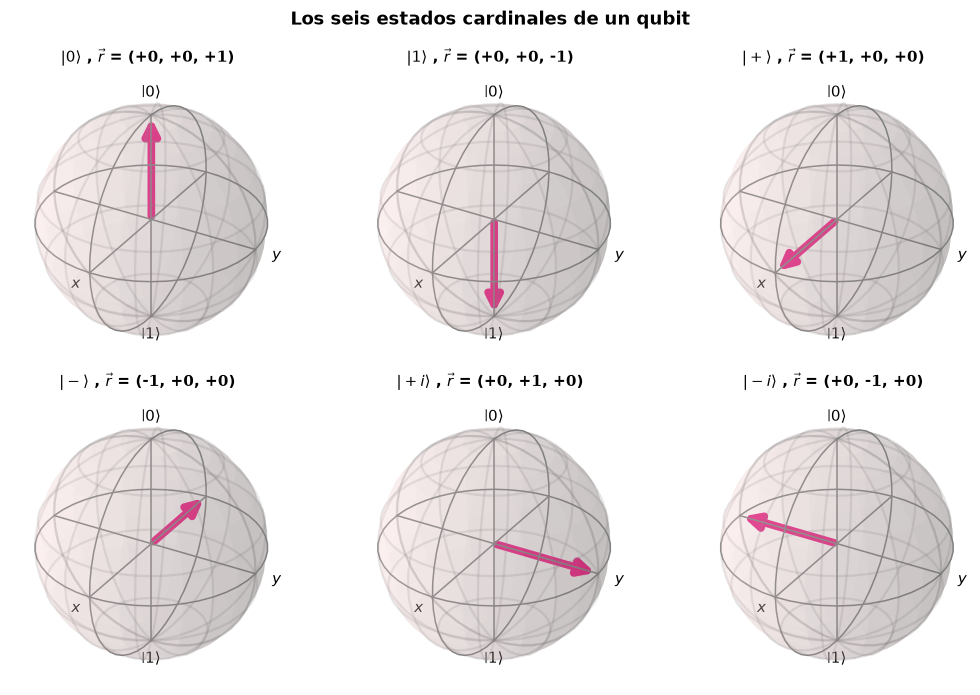

In [8]:
# Los seis puntos cardinales de la esfera, cada uno con el circuito que lo prepara.
preparaciones = {
    r"$|0\rangle$":  QuantumCircuit(1),
    r"$|1\rangle$":  QuantumCircuit(1),
    r"$|+\rangle$":  QuantumCircuit(1),
    r"$|-\rangle$":  QuantumCircuit(1),
    r"$|+i\rangle$": QuantumCircuit(1),
    r"$|-i\rangle$": QuantumCircuit(1),
}
preparaciones[r"$|1\rangle$"].x(0)
preparaciones[r"$|+\rangle$"].h(0)
preparaciones[r"$|-\rangle$"].x(0); preparaciones[r"$|-\rangle$"].h(0)
preparaciones[r"$|+i\rangle$"].h(0); preparaciones[r"$|+i\rangle$"].s(0)
preparaciones[r"$|-i\rangle$"].h(0); preparaciones[r"$|-i\rangle$"].sdg(0)

fig, ejes = plt.subplots(2, 3, figsize=(9.5, 6.4),
                         subplot_kw={"projection": "3d"})
for ax, (nombre, qc) in zip(ejes.ravel(), preparaciones.items()):
    sv = Statevector(qc)
    r = [np.real(sv.expectation_value(Pauli(p))) for p in "XYZ"]
    plot_bloch_vector(r, ax=ax)
    ax.set_title(f"{nombre} , $\\vec r$ = ({r[0]:+.0f}, {r[1]:+.0f}, {r[2]:+.0f})\n\n",
                 fontsize=10)
fig.suptitle("Los seis estados cardinales de un qubit", fontweight="bold")
fig.tight_layout()
plt.show()

Los seis estados son autoestados de las tres Paulis: $|0\rangle,|1\rangle$
de
$Z$; $|\pm\rangle$ de $X$; $|{\pm}i\rangle$ de $Y$. Cada vector de Bloch
tiene una sola componente distinta de cero, y vale exactamente $\pm 1$:
esa es la firma de "autoestado de esa Pauli".

El dato importante para después: **$|+\rangle$ tiene $\langle Z\rangle =
0$**.
Está tan arriba como abajo. Si se lo mide en $Z$, sale cara o ceca.

---
# 2. Las compuertas son rotaciones

Toda compuerta de un qubit es una rotación de la esfera de Bloch. Las que
importan:

| Compuerta | Qué hace en la esfera | Matriz |
|---|---|---|
| $X$ | giro de $180°$ alrededor de $\hat x$ | $\begin{pmatrix}0&1\\1&0\end{pmatrix}$ |
| $Z$ | giro de $180°$ alrededor de $\hat z$ | $\begin{pmatrix}1&0\\0&-1\end{pmatrix}$ |
| $H$ | giro de $180°$ alrededor de $(\hat x + \hat z)/\sqrt2$ | $\tfrac1{\sqrt2}\begin{pmatrix}1&1\\1&-1\end{pmatrix}$ |
| $S$ | giro de $90°$ alrededor de $\hat z$ | $\mathrm{diag}(1, i)$ |
| $T$ | giro de $45°$ alrededor de $\hat z$ | $\mathrm{diag}(1, e^{i\pi/4})$ |
| $R_y(\theta)$ | giro de $\theta$ alrededor de $\hat y$ | — |

$H$ es la que hace todo el trabajo en este curso: manda $|0\rangle \to
|+\rangle$, o sea que **crea superposición**, y es su propia inversa.

Veamos $R_y(\theta)$ moviendo el estado continuamente del polo norte al sur.

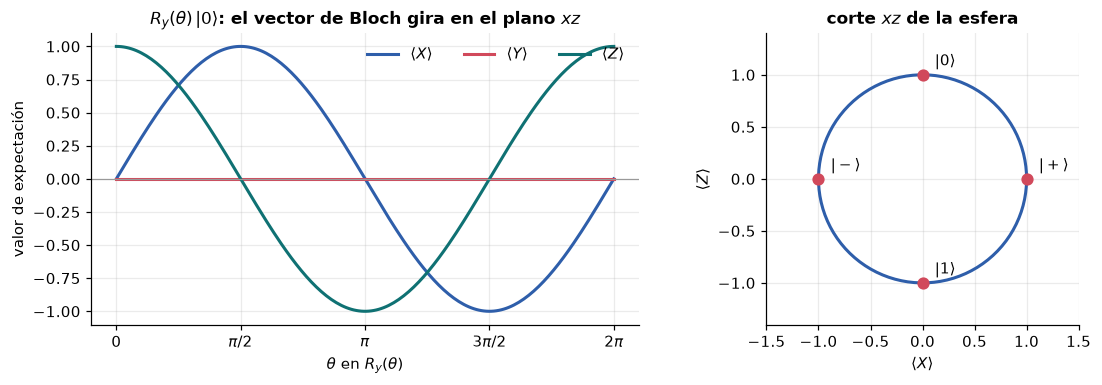

In [9]:
thetas = np.linspace(0, 2 * np.pi, 200)
componentes = []
for th in thetas:
    qc = QuantumCircuit(1)
    qc.ry(th, 0)
    sv = Statevector(qc)
    componentes.append([np.real(sv.expectation_value(Pauli(p))) for p in "XYZ"])
componentes = np.array(componentes)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.6),
                               gridspec_kw={"width_ratios": [1.3, 1]})

for i, (etiqueta, color) in enumerate(zip([r"$\langle X\rangle$",
                                           r"$\langle Y\rangle$",
                                           r"$\langle Z\rangle$"],
                                          utils.PALETA)):
    ax1.plot(thetas, componentes[:, i], label=etiqueta, color=color, lw=2)
ax1.set_xlabel(r"$\theta$ en $R_y(\theta)$")
ax1.set_ylabel("valor de expectación")
ax1.set_title(r"$R_y(\theta)\,|0\rangle$: el vector de Bloch gira en el plano $xz$")
ax1.set_xticks(np.linspace(0, 2 * np.pi, 5))
ax1.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
ax1.axhline(0, color="0.6", lw=0.8)
ax1.legend(ncol=3)

ax2.plot(componentes[:, 0], componentes[:, 2], color=utils.COLOR_IDEAL, lw=2)
circ = plt.Circle((0, 0), 1, fill=False, ls="--", color="0.6")
ax2.add_patch(circ)
for th, nombre in [(0, r"$|0\rangle$"), (np.pi / 2, r"$|+\rangle$"),
                   (np.pi, r"$|1\rangle$"), (3 * np.pi / 2, r"$|-\rangle$")]:
    ax2.plot(np.sin(th), np.cos(th), "o", color=utils.COLOR_RUIDO, ms=7)
    ax2.annotate(nombre, (np.sin(th), np.cos(th)),
                 textcoords="offset points", xytext=(8, 6))
ax2.set_aspect("equal")
ax2.set_xlabel(r"$\langle X\rangle$")
ax2.set_ylabel(r"$\langle Z\rangle$")
ax2.set_title("corte $xz$ de la esfera")
ax2.set_xlim(-1.5, 1.5); ax2.set_ylim(-1.4, 1.4)
fig.tight_layout()
plt.show()

La curva de la derecha es el círculo completo: $R_y$ recorre el meridiano
$y=0$. Con $\theta = \pi/2$ se cae justo en $|+\rangle$ — es decir,
$R_y(\pi/2)$
hace lo mismo que $H$ salvo una fase. Y hace falta $\theta = 2\pi$ para
volver
al punto de partida en la esfera, aunque el *estado* vuelva con un signo
menos:
esa es la famosa fase de $4\pi$ de los espines $1/2$, que la esfera de Bloch
esconde porque la fase global no se ve.

---
# 3. Medir: la regla de Born

Medir en la base computacional colapsa el estado a $|0\rangle$ o
$|1\rangle$,
con probabilidades

$$P(0) = |\langle 0|\psi\rangle|^2, \qquad P(1) = |\langle 1|\psi\rangle|^2.$$

Para $|\psi\rangle = R_y(\theta)|0\rangle$ eso da

$$P(0) = \cos^2\frac{\theta}{2}, \qquad P(1) = \sin^2\frac{\theta}{2}.$$

Esto **no se deriva**: es un postulado. Lo único que podemos hacer es
medirlo.
Y es el experimento más honesto que hay para abrir un curso, porque la
predicción es una curva suave y los datos son conteos discretos con
fluctuación binomial: se ve la estadística trabajando.

Vamos a preparar $R_y(\theta)|0\rangle$ para 13 valores de $\theta$ y
contar.
**Un circuito por ángulo, todos en la misma lista** — cuando esto vaya a
hardware va a ser un solo job.

[0.         0.52359878 1.04719755 1.57079633 2.0943951  2.61799388
 3.14159265 3.66519143 4.1887902  4.71238898 5.23598776 5.75958653
 6.28318531]
Un circuito del barrido (θ = π/3):


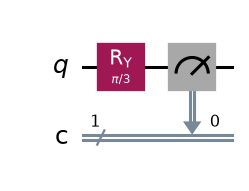

In [ ]:
angulos = np.linspace(0, 2 * np.pi, 13)
SHOTS = 4096

circuitos_born = []
print(angulos)
for th in angulos:
    qc = QuantumCircuit(1, 1)
    qc.ry(th, 0)
    qc.measure(0, 0)
    circuitos_born.append(qc)

print("Un circuito del barrido (θ = π/3):")
qc_ejemplo = QuantumCircuit(1, 1)
qc_ejemplo.ry(np.pi / 3, 0)
qc_ejemplo.measure(0, 0)
display(qc_ejemplo.draw("mpl", style="iqp"))

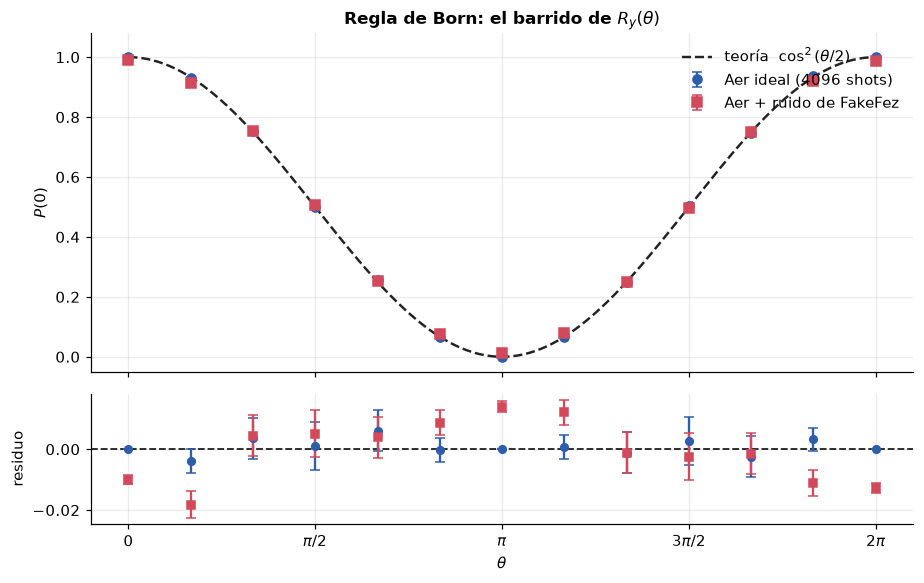

desviación RMS ideal   : 0.0027
desviación RMS FakeFez : 0.0096
error binomial típico  : 0.0045


In [12]:
counts_ideal = utils.correr_ideal(circuitos_born, shots=SHOTS)
counts_ruido = utils.correr_ruidoso(circuitos_born, backend_falso=fez, shots=SHOTS)

p0_ideal = np.array([c.get("0", 0) / SHOTS for c in counts_ideal])
p0_ruido = np.array([c.get("0", 0) / SHOTS for c in counts_ruido])
err_ideal = np.sqrt(p0_ideal * (1 - p0_ideal) / SHOTS)
err_ruido = np.sqrt(p0_ruido * (1 - p0_ruido) / SHOTS)
p0_teoria = np.cos(angulos / 2) ** 2

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8.5, 5.4), sharex=True,
                               gridspec_kw={"height_ratios": [2.6, 1]})

th_fino = np.linspace(0, 2 * np.pi, 400)
ax1.plot(th_fino, np.cos(th_fino / 2) ** 2, color=utils.COLOR_TEORIA, lw=1.6,
         ls="--", label=r"teoría  $\cos^2(\theta/2)$")
ax1.errorbar(angulos, p0_ideal, yerr=err_ideal, fmt="o", ms=6, capsize=3,
             color=utils.COLOR_IDEAL, label=f"Aer ideal ({SHOTS} shots)")
ax1.errorbar(angulos, p0_ruido, yerr=err_ruido, fmt="s", ms=6, capsize=3,
             color=utils.COLOR_RUIDO, label="Aer + ruido de FakeFez")
ax1.set_ylabel(r"$P(0)$")
ax1.set_title("Regla de Born: el barrido de $R_y(\\theta)$")
ax1.set_ylim(-0.05, 1.08)
ax1.legend(loc="upper right")

ax2.axhline(0, color=utils.COLOR_TEORIA, lw=1.2, ls="--")
ax2.errorbar(angulos, p0_ideal - p0_teoria, yerr=err_ideal, fmt="o", ms=5,
             capsize=3, color=utils.COLOR_IDEAL)
ax2.errorbar(angulos, p0_ruido - p0_teoria, yerr=err_ruido, fmt="s", ms=5,
             capsize=3, color=utils.COLOR_RUIDO)
ax2.set_ylabel("residuo")
ax2.set_xlabel(r"$\theta$")
ax2.set_xticks(np.linspace(0, 2 * np.pi, 5))
ax2.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
fig.tight_layout()
plt.show()

print(f"desviación RMS ideal   : {np.sqrt(np.mean((p0_ideal - p0_teoria)**2)):.4f}")
print(f"desviación RMS FakeFez : {np.sqrt(np.mean((p0_ruido - p0_teoria)**2)):.4f}")
print(f"error binomial típico  : {np.mean(err_ideal):.4f}")

**Cómo leer el panel de residuos.** El simulador ideal se pega a cero dentro
de
las barras de error: la única discrepancia es la estadística de 4096
tiradas.
El simulador con ruido, en cambio, se despega de forma **sistemática** —
típicamente hacia el centro, comprimiendo el contraste. Eso es el error de
lectura del detector: hay una probabilidad de unos pocos por ciento de leer
1
cuando el estado era 0, y viceversa. El efecto es achatar la curva, no
ensucharla al azar.

Es exactamente el sesgo que vamos a ver en el hardware real cuando se corra la
última sección, y es un buen momento de clase: lo que en NISQ se llama ruido
se comporta como **sesgo**.

### Medir en otras bases

La medición de Qiskit siempre es en $Z$. Para medir $X$ hay que rotar el eje
que te interesa hasta $Z$ y recién ahí medir:

- medir $X$ $\;\to\;$ aplicar $H$, después medir;
- medir $Y$ $\;\to\;$ aplicar $S^\dagger$ y $H$, después medir;
- medir $Z$ $\;\to\;$ medir.

Con eso se reconstruye el vector de Bloch entero a partir de conteos. Es
tomografía de un qubit, y es la herramienta que en el 03 va a servir para
verificar la teleportación.

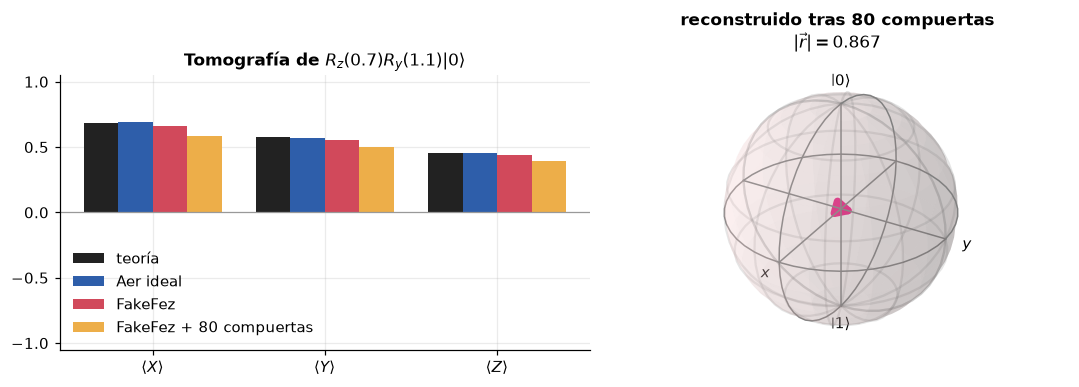

error estadístico por componente: ±0.0078  (16384 shots)
|r| teoría              = 1.0000   (estado puro: vale 1)
|r| Aer ideal           = 0.9993
|r| FakeFez, circuito corto = 0.9699
|r| FakeFez, 80 compuertas  = 0.8667   <- adentro de la esfera


In [13]:
def circuitos_tomografia(prep: QuantumCircuit) -> list[QuantumCircuit]:
    """Tres circuitos: el mismo estado medido en X, en Y y en Z."""
    circuitos = []
    for base in "XYZ":
        qc = prep.copy()
        qc.add_register(__import__("qiskit").ClassicalRegister(1, "c"))
        if base == "X":
            qc.h(0)
        elif base == "Y":
            qc.sdg(0); qc.h(0)
        qc.measure(0, 0)
        circuitos.append(qc)
    return circuitos


def bloch_medido(counts_xyz, shots):
    """<P> = P(0) - P(1) para cada base."""
    return np.array([(c.get("0", 0) - c.get("1", 0)) / shots for c in counts_xyz])


# Un estado cualquiera, ni cardinal ni simétrico.
theta_t, phi_t = 1.1, 0.7
prep = QuantumCircuit(1)
prep.ry(theta_t, 0)
prep.rz(phi_t, 0)

# Y el mismo estado, pero castigado: 40 pares X·X que idealmente no hacen nada.
prep_larga = prep.copy()
for _ in range(40):
    prep_larga.x(0)
    prep_larga.x(0)

SHOTS_TOMO = 16384
tomo = circuitos_tomografia(prep)
tomo_largo = circuitos_tomografia(prep_larga)

r_ideal = bloch_medido(utils.correr_ideal(tomo, shots=SHOTS_TOMO), SHOTS_TOMO)
r_ruido = bloch_medido(utils.correr_ruidoso(tomo, backend_falso=fez, shots=SHOTS_TOMO),
                       SHOTS_TOMO)
# opt=0 para que el transpilador NO cancele los pares X·X: queremos que el
# circuito largo efectivamente se ejecute largo.
r_largo = bloch_medido(utils.correr_ruidoso(tomo_largo, backend_falso=fez,
                                            shots=SHOTS_TOMO, opt=0), SHOTS_TOMO)
sv = Statevector(prep)
r_teoria = np.array([np.real(sv.expectation_value(Pauli(p))) for p in "XYZ"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.6),
                               gridspec_kw={"width_ratios": [1.15, 1]})
x = np.arange(3)
ax1.bar(x - 0.30, r_teoria, 0.2, label="teoría", color=utils.COLOR_TEORIA)
ax1.bar(x - 0.10, r_ideal, 0.2, label="Aer ideal", color=utils.COLOR_IDEAL)
ax1.bar(x + 0.10, r_ruido, 0.2, label="FakeFez", color=utils.COLOR_RUIDO)
ax1.bar(x + 0.30, r_largo, 0.2, label="FakeFez + 80 compuertas",
        color=utils.PALETA[3])
ax1.set_xticks(x)
ax1.set_xticklabels([r"$\langle X\rangle$", r"$\langle Y\rangle$", r"$\langle Z\rangle$"])
ax1.axhline(0, color="0.6", lw=0.8)
ax1.set_ylim(-1.05, 1.05)
ax1.set_title(f"Tomografía de $R_z({phi_t})R_y({theta_t})|0\\rangle$")
ax1.legend()

ax2.axis("off")
ax2 = fig.add_subplot(1, 2, 2, projection="3d")
plot_bloch_vector(list(r_largo), ax=ax2)
ax2.set_title(f"reconstruido tras 80 compuertas\n$|\\vec r| = "
              f"{np.linalg.norm(r_largo):.3f}$\n\n")
fig.tight_layout()
plt.show()

err_r = 1 / np.sqrt(SHOTS_TOMO)   # error típico por componente
print(f"error estadístico por componente: ±{err_r:.4f}  ({SHOTS_TOMO} shots)")
print(f"|r| teoría              = {np.linalg.norm(r_teoria):.4f}   (estado puro: vale 1)")
print(f"|r| Aer ideal           = {np.linalg.norm(r_ideal):.4f}")
print(f"|r| FakeFez, circuito corto = {np.linalg.norm(r_ruido):.4f}")
print(f"|r| FakeFez, 80 compuertas  = {np.linalg.norm(r_largo):.4f}   <- adentro de la esfera")

Ahí está el primer dato duro del curso. Con un circuito de tres compuertas
el
ruido casi no se nota: $|\vec r|$ se despega de 1 por menos de lo que vale
la
barra de error estadística, así que con esos datos solos no podrías afirmar
nada. Por eso está la cuarta barra.

El circuito castigado son 40 pares $X\cdot X$: **80 compuertas que en teoría
no
hacen absolutamente nada**, porque $X^2 = I$. La teoría dice que el estado
final es idéntico. El chip dice otra cosa: $|\vec r|$ cae claramente por
debajo de 1, muy por fuera del error estadístico.

El estado reconstruido **ya no es puro**. La decoherencia no lo lleva a otro
estado puro: lo convierte en una mezcla estadística, un punto *interior* de
la
esfera. El límite de esa caída es $|\vec r| = 0$, el centro, que es el
estado
máximamente mezclado — ninguna información. Cuanto más largo el circuito,
más
adentro cae, y eso es, en una sola figura, por qué NISQ tiene un techo de
profundidad.

---
# 4. Stern-Gerlach: bases que no conmutan

El experimento de 1922 no necesita un circuito complicado, necesita **medir
en
el orden correcto**. La versión de tres imanes:

1. Un haz sin polarizar entra a un imán orientado en $\hat z$. Se parte en
dos.
   Nos quedamos con el de arriba: ahora se tiene un haz puro
     $|{\uparrow_z}\rangle$.
2. Ese haz entra a un imán orientado en $\hat x$. **Se vuelve a partir en
dos**,
   mitad y mitad. Clásicamente esto ya es raro, pero se puede racionalizar.
3. El haz $|{\uparrow_x}\rangle$ que sale de ahí entra a un tercer imán,
otra
   vez en $\hat z$. Si el espín "tuviera" un valor de $z$ definido desde el
   paso 1, tendría que salir todo por arriba.

**Sale mitad y mitad.** La medición en $x$ no le agregó una propiedad: le
*borró* la de $z$. Eso es lo que significa que $X$ y $Z$ no conmuten,
$[X, Z] = -2iY \ne 0$.

En el circuito, "un imán en $\hat x$" es: $H$, medir, $H$ (para volver al
marco del laboratorio). Y "quedarse con el haz de arriba" es
post-seleccionar
los shots donde ese bit salió 0 — el equivalente cuántico de tapar la salida
de abajo con una placa de plomo.

**Atención al orden de los bits:** en la cadena de counts, el bit clásico 0
es
el de la derecha. Una cuenta `'011'` quiere decir $c_2=0$, $c_1=1$, $c_0=1$.

### La fuente: un horno, no un estado $|+\rangle$

Un detalle que es fácil pasar por alto y que importa. El haz que sale de un
horno tiene los espines orientados **al azar**: eso es una mezcla
estadística,
$\rho = I/2$, el centro de la esfera de Bloch. $|+\rangle$ es otra cosa: un
estado *puro* apuntando a $+\hat x$. Los dos dan 50/50 al medir en $z$, pero
se distinguen en un solo tiro midiendo en $x$.

Acá el horno se construye con un **qubit auxiliar entrelazado**: preparamos
$|\Phi^+\rangle$ y nunca miramos el segundo qubit. El estado reducido del
primero es exactamente $I/2$.

### Las barreras están numeradas

El circuito lleva barreras ① a ⑥, y cada número tiene su línea de cuenta acá
abajo. Son los puntos donde el estado del átomo cambia de forma:

**①** Salida del horno: $\rho_1 =
\mathrm{Tr}_{\text{anc}}|\Phi^+\rangle\langle\Phi^+| = I/2$.

**②** Dado que se mide $Z$ y el plomo se queda con la rama de arriba, el
estado
condicionado es puro: $|\psi_2\rangle = |0\rangle$.

**③** Dado que se aplica $H$ para entrar al marco del imán de $x$:
$|\psi_3\rangle = H|0\rangle = (|0\rangle+|1\rangle)/\sqrt2$, que es la
reescritura $|0\rangle = (|+\rangle+|-\rangle)/\sqrt2$: el haz se parte.

**④** Dado que se mide en ese marco y filtramos el resultado $0$ (la rama
$+\hat x$): $|\psi_4\rangle = |0\rangle$ en el marco rotado.

**⑤** Dado que se aplica $H$ para volver al marco del laboratorio:
$|\psi_5\rangle = |+\rangle$. El átomo apunta a $+\hat x$, sobre el ecuador.

**⑥** Dado que el imán 3 mide $Z$ sobre $|+\rangle$, y
$|+\rangle = (|0\rangle+|1\rangle)/\sqrt2$:
$$P(\uparrow_z) = |\langle 0|+\rangle|^2 = \tfrac12 .$$

La información de $z$ se perdió en **④**, el único paso no unitario: ③ y ⑤
son
$H$ y $H$, y $H^2 = I$. Sacar la medición de ④ y el 100 % arriba vuelve — eso
se demuestra en `01b_stern_gerlach.ipynb`, que desarma este experimento caso
por caso, con esferas de Bloch en cada etapa.

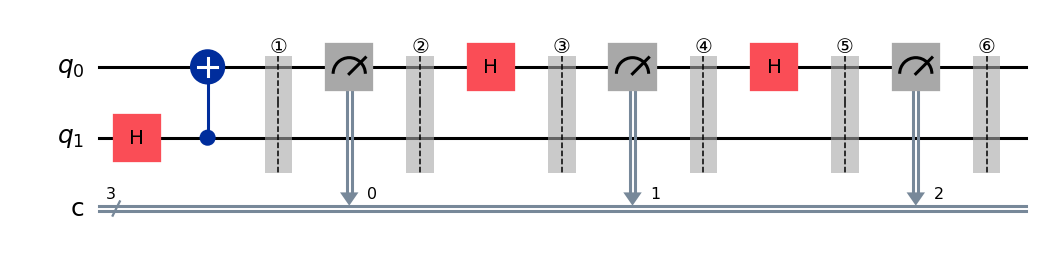

In [8]:
MARCAS = "①②③④⑤⑥⑦⑧⑨"


def marca(qc, n):
    """Barrera numerada: señala el punto del circuito donde el texto de arriba
    calcula el estado del átomo."""
    qc.barrier(label=MARCAS[n - 1])
    return qc


def horno(n_clbits):
    """El haz del horno: qubit 0 = átomo, qubit 1 = ancilla que nunca se mide.
    El estado reducido del átomo es exactamente rho = I/2."""
    qc = QuantumCircuit(2, n_clbits)
    qc.h(1)
    qc.cx(1, 0)
    return marca(qc, 1)


# Imán 1: Z.   Imán 2: X (rotar, medir, volver).   Imán 3: Z.
sg = horno(3)
sg.measure(0, 0); marca(sg, 2)
sg.h(0); marca(sg, 3)
sg.measure(0, 1); marca(sg, 4)
sg.h(0); marca(sg, 5)
sg.measure(0, 2); marca(sg, 6)

# Control: los mismos tres imanes, pero el del medio también en z.
sg_zzz = horno(3)
sg_zzz.measure(0, 0); marca(sg_zzz, 2)
sg_zzz.measure(0, 1); marca(sg_zzz, 4)
sg_zzz.measure(0, 2); marca(sg_zzz, 6)

display(sg.draw("mpl", style="iqp", fold=-1))

In [9]:
SHOTS_SG = 8192
c_zxz = utils.correr_ideal(sg, shots=SHOTS_SG)
c_zzz = utils.correr_ideal(sg_zzz, shots=SHOTS_SG)
c_zxz_ruido = utils.correr_ruidoso(sg, backend_falso=fez, shots=SHOTS_SG)


# Tapar una salida del imán con plomo = quedarse con los shots cuyo bit vale 0.
# utils.filtrar hace exactamente eso, cuidando el orden little-endian de Qiskit.
tercer_iman_zxz = utils.filtrar(c_zxz, {0: "0", 1: "0"}, mantener=[2])
tercer_iman_zzz = utils.filtrar(c_zzz, {0: "0", 1: "0"}, mantener=[2])
tercer_zxz_ruido = utils.filtrar(c_zxz_ruido, {0: "0", 1: "0"}, mantener=[2])

n1, n2 = sum(tercer_iman_zxz.values()), sum(tercer_iman_zzz.values())
print(f"Z-X-Z  tras filtrar z↑ y x↑ ({n1} shots): {tercer_iman_zxz}")
print(f"Z-Z-Z  tras filtrar z↑ y z↑ ({n2} shots): {tercer_iman_zzz}")

Z-X-Z  tras filtrar z↑ y x↑ (2095 shots): {'1': 1079, '0': 1016}
Z-Z-Z  tras filtrar z↑ y z↑ (4153 shots): {'0': 4153}


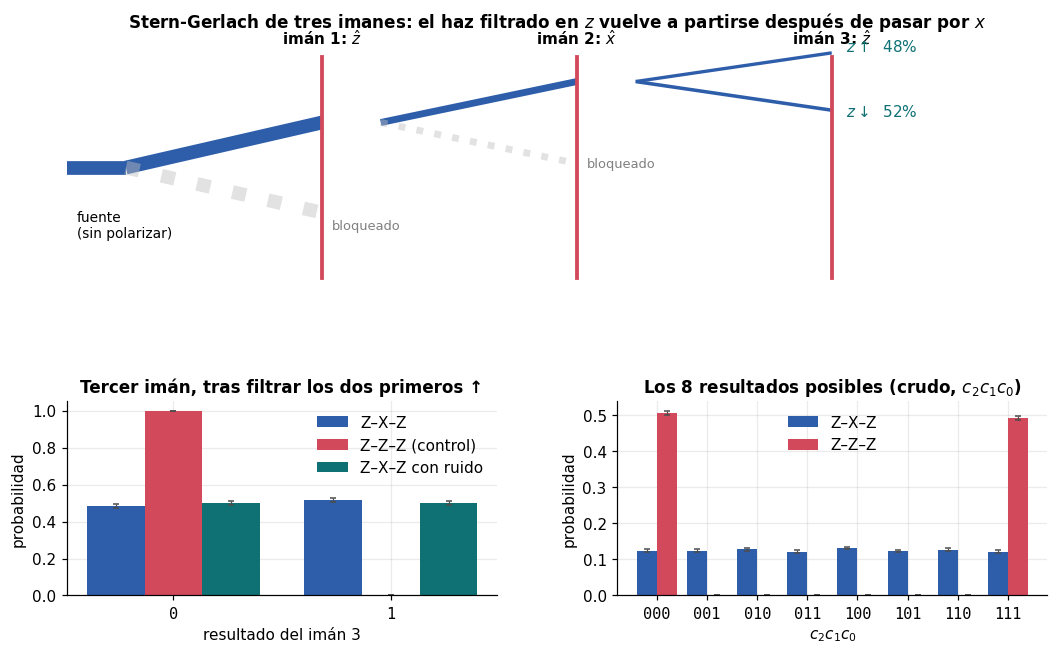

In [10]:
fig = plt.figure(figsize=(11.5, 6.6))
gs = fig.add_gridspec(2, 2, height_ratios=[1.35, 1], hspace=0.45, wspace=0.28)

# --- panel superior: la cascada de haces, ancho proporcional a la intensidad ---
ax = fig.add_subplot(gs[0, :])
ax.set_axis_off()
ax.set_xlim(0, 10); ax.set_ylim(-1.6, 1.6)

p_z2 = tercer_iman_zxz.get("0", 0) / max(n1, 1)
etapas = [
    # (x0, x1, y0, y1, intensidad, bloqueado)
    (0.6, 2.6,  0.0,  0.55, 0.50, False),   # imán 1: arriba (pasa)
    (0.6, 2.6,  0.0, -0.55, 0.50, True),    # imán 1: abajo  (bloqueado)
    (3.2, 5.2,  0.55, 1.05, 0.25, False),   # imán 2: +x (pasa)
    (3.2, 5.2,  0.55, 0.05, 0.25, True),    # imán 2: -x (bloqueado)
    (5.8, 7.8,  1.05, 1.40, 0.25 * p_z2, False),
    (5.8, 7.8,  1.05, 0.70, 0.25 * (1 - p_z2), False),
]
ax.plot([0.0, 0.6], [0, 0], color=utils.COLOR_IDEAL, lw=9, solid_capstyle="butt")
ax.annotate("fuente\n(sin polarizar)", (0.05, 0), xytext=(0.1, -0.85), fontsize=9)
for x0, x1, y0, y1, inten, bloq in etapas:
    ax.plot([x0, x1], [y0, y1],
            color="0.75" if bloq else utils.COLOR_IDEAL,
            lw=max(1.5, 18 * inten), alpha=0.45 if bloq else 1.0,
            ls=":" if bloq else "-", solid_capstyle="butt")
for x, etiqueta in [(2.9, r"imán 1: $\hat z$"), (5.5, r"imán 2: $\hat x$"),
                    (8.1, r"imán 3: $\hat z$")]:
    ax.axvline(x - 0.3, color=utils.COLOR_RUIDO, lw=2.5, ymin=0.08, ymax=0.92)
    ax.text(x - 0.3, 1.5, etiqueta, ha="center", fontsize=10, fontweight="bold")
ax.text(2.7, -0.75, "bloqueado", color="0.5", fontsize=8.5)
ax.text(5.3, 0.0, "bloqueado", color="0.5", fontsize=8.5)
ax.text(7.95, 1.42, f"$z\\uparrow$  {p_z2:.0%}", fontsize=10, color=utils.COLOR_HARD)
ax.text(7.95, 0.62, f"$z\\downarrow$  {1 - p_z2:.0%}", fontsize=10, color=utils.COLOR_HARD)
ax.set_title("Stern-Gerlach de tres imanes: el haz filtrado en $z$ vuelve a partirse "
             "después de pasar por $x$", fontweight="bold")

# --- panel inferior izquierdo: Z-X-Z vs Z-Z-Z en el tercer imán ---
ax1 = fig.add_subplot(gs[1, 0])
utils.comparar_conteos(
    {"Z–X–Z": tercer_iman_zxz, "Z–Z–Z (control)": tercer_iman_zzz,
     "Z–X–Z con ruido": tercer_zxz_ruido},
    claves=["0", "1"], ax=ax1,
    titulo="Tercer imán, tras filtrar los dos primeros ↑")
ax1.set_xlabel("resultado del imán 3")

# --- panel inferior derecho: el histograma crudo de los 3 bits ---
ax2 = fig.add_subplot(gs[1, 1])
utils.comparar_conteos({"Z–X–Z": c_zxz, "Z–Z–Z": c_zzz},
                       claves=utils.claves_completas(3), ax=ax2,
                       titulo="Los 8 resultados posibles (crudo, $c_2c_1c_0$)")
ax2.set_xlabel("$c_2 c_1 c_0$")
plt.show()

**El panel de abajo a la derecha es el que cierra el argumento.** En la
secuencia Z–Z–Z aparecen exactamente **dos** cadenas de las ocho posibles:
`000` y `111`. Los tres imanes dan siempre el mismo resultado, porque medir
$Z$ dos veces seguidas no cambia nada: el primer colapso ya dejó al estado
en
un autoestado de $Z$, y ahí se queda. Las otras seis cadenas tienen
probabilidad cero.

En la secuencia Z–X–Z aparecen las **ocho**. El imán del medio destruyó la
correlación entre el primero y el tercero. Dicho de otro modo: después del
imán 2, la pregunta "¿cuánto valía $z$?" no tiene respuesta guardada en
ningún
lado.

En el panel de la izquierda, la barra de Z–X–Z está en 50/50 y la de control
en 100/0. (El desarrollo completo, caso por caso y con esferas de Bloch en
cada etapa, está en `01b_stern_gerlach.ipynb`.) La versión con ruido se
corre unos puntos del 50 % — y acá el ruido
casi no molesta, porque el resultado *es* el azar máximo: es difícil
ensuciar
una moneda justa. Esa es la razón por la que este experimento sale bien en
hardware NISQ, y la vamos a comprobar en la sección siguiente.

---
# 5. Envío a hardware real

Todo lo de arriba corrió en simulador. Esta sección es la única que gasta
tiempo de QPU, y **no se ejecuta sola**: cada bloque tiene su flag en
`False`.

Recordemos el presupuesto: **10 minutos de QPU por ventana móvil de 28 días**.
Un job de este notebook cuesta unos pocos segundos, pero el overhead por job
es lo que se acumula: hay que mandar muchos circuitos juntos y pocos jobs.

Orden de trabajo:

1. Correr la celda de autenticación de arriba con `AUTENTICAR = True`.
2. Elegir backend (celda siguiente). **El backend se fija antes de
transpilar**:
   la transpilación depende del coupling map y de los errores de ese chip.
3. Mirar el informe de costo.
4. Recién ahí poner el flag en `True` y correr esa celda sola.
5. Anotar el `job_id` (se escribe solo en `jobs.jsonl`) y **no esperar la
cola**.
   Volvés más tarde con la sección de recuperación.

In [ ]:
# Panorama antes de elegir: qué hay, cuánta cola tiene cada uno, y si de verdad
# está operativo. Una cola en 0 puede significar "libre" o "reservado": el único
# status_msg que sirve es 'active'.
if service is not None:
    print(f"{'backend':<16} {'qubits':>6} {'cola':>6}  {'estado':<10} procesador")
    print("-" * 62)
    for b in service.backends(simulator=False):
        st = b.status()
        tipo = b.processor_type or {}
        print(f"{b.name:<16} {b.num_qubits:>6} {st.pending_jobs:>6}  "
              f"{st.status_msg:<10} {tipo.get('family', '')} r{tipo.get('revision', '')}")
else:
    print("sin autenticar: correr la celda de autenticación de arriba")

In [ ]:
# Elegir uno. Dejarlo en None para que tome el menos ocupado, o poner un nombre
# para fijarlo. Atención: el nombre lleva el prefijo — es "ibm_fez", no "fez".
BACKEND_FIJO = None      # p.ej. "ibm_fez"

backend = None
if service is not None:
    if BACKEND_FIJO:
        backend = service.backend(BACKEND_FIJO)
    else:
        backend = service.least_busy(operational=True, simulator=False)
    st = backend.status()
    print(f"elegido: {backend.name}")
    print(f"  estado    : {st.status_msg}   (solo 'active' sirve)")
    print(f"  cola      : {st.pending_jobs} jobs")
    print(f"  qubits    : {backend.num_qubits}  {backend.processor_type}")
else:
    print("sin autenticar: no hay backend. Correr la celda de autenticación de arriba.")

sin autenticar: no hay backend. Correr la celda de autenticación de arriba.


In [ ]:
# Transpilación contra el backend elegido. Sin esto no se manda nada.
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

SHOTS_HW = 1024
t_born = t_sg = None

if backend is not None:
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    t_born = pm.run(circuitos_born)
    t_sg = pm.run([sg, sg_zzz])

    print("=== Experimento A: barrido de Born ===")
    costo_a = utils.informe_transpilacion(t_born, shots=SHOTS_HW,
                                          nombre_backend=backend.name)
    print("\n=== Experimento B: Stern-Gerlach ===")
    costo_b = utils.informe_transpilacion(t_sg, shots=SHOTS_HW,
                                          nombre_backend=backend.name)
    print(f"\ntotal si mandás los dos: ~{costo_a + costo_b:.1f} s de QPU")
else:
    print("sin backend: nada que transpilar")

sin backend: nada que transpilar


### Mirar el circuito transpilado antes de mandarlo

Lo que se ejecuta en el chip no se parece a lo que escribiste. Las
compuertas quedan reescritas en la base física de Heron
—`rz`, `sx`, `x`, `cz`— y el circuito se asigna a qubits físicos concretos,
elegidos por el transpilador según cuáles tienen menos error ese día.

Dos detalles que ahorran una vuelta:

- **`idle_wires=False` no es opcional.** El circuito transpilado formalmente
  tiene 156 qubits, así que sin eso el dibujo sale con 150 cables vacíos.
- El objeto es un `QuantumCircuit`, se dibuja con `.draw("mpl")`. No tiene
  `.mpl()` ni `.display()`. Y `t_sg` es una *lista*: hay que indexarla.

`final_index_layout()` dice a qué qubits físicos fue a parar cada qubit
lógico. Sirve para cruzarlo con los errores de lectura del chip.

In [ ]:
if t_sg is not None:
    print(f"qubits físicos usados: {t_sg[0].layout.final_index_layout()}")
    print(f"profundidad: {t_sg[0].depth()}   compuertas: {dict(t_sg[0].count_ops())}")
    display(t_sg[0].draw("mpl", idle_wires=False, fold=-1, style="iqp"))
else:
    print("sin transpilar: no hay nada que dibujar")

sin transpilar: no hay nada que dibujar


### Experimento A — el barrido de Born en el chip

13 circuitos de un qubit, profundidad ~2 después de transpilar. Es lo más
barato y lo más claro que se puede correr en hardware real: la curva
$\cos^2(\theta/2)$ sale prácticamente perfecta, apenas achatada por el error
de lectura. Es la demostración de apertura ideal.

In [ ]:
ENVIAR_BORN = False    # ponerlo en True para gastar QPU

if ENVIAR_BORN:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_born, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"01 Born: barrido Ry de {len(t_born)} angulos, {SHOTS_HW} shots",
                        notebook="01", experimento="born", n_circuitos=len(t_born),
                        shots=SHOTS_HW, circuitos=t_born,
                        angulos=list(np.round(angulos, 5)))
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


### Experimento B — Stern-Gerlach en el chip

Este tiene **mediciones a mitad de circuito**, que en Heron son caras y
ruidosas:
cada una toma del orden de microsegundos durante los cuales el qubit se
decohera. Esperá ver el control Z–Z–Z con un pequeño porcentaje de cadenas
"imposibles" (`010`, `101`, etc.): eso es exactamente el error de lectura y
de
relajación, y es material de clase, no un fracaso.

In [ ]:
ENVIAR_SG = False      # ponerlo en True para gastar QPU

if ENVIAR_SG:
    from qiskit_ibm_runtime import SamplerV2

    job = SamplerV2(mode=backend).run(t_sg, shots=SHOTS_HW)
    utils.registrar_job(job, backend.name,
                        f"01 Stern-Gerlach: Z-X-Z y control Z-Z-Z, {SHOTS_HW} shots",
                        notebook="01", experimento="stern_gerlach",
                        n_circuitos=len(t_sg), shots=SHOTS_HW, circuitos=t_sg)
else:
    print("modo simulación — no se envió nada")

modo simulación — no se envió nada


---
# 6. Recuperar resultados

Nunca esperar la cola en vivo. Se manda, se guarda el `job_id`, se cierra la
laptop.
Cuando vuelvas, esta sección trae los resultados por id.

Un `job_id` perdido es tiempo de QPU perdido: por eso se escribe a
`jobs.jsonl` dentro del `if`, en la misma celda que el envío.

In [ ]:
registros = utils.listar_jobs(filtro="01 ")

2026-09-17T00:13:00  ibm_fez          dalj12opqrnc73967d7g  01 Stern-Gerlach: Z-X-Z y control Z-Z-Z, 1024 shots


### Traer el barrido de Born

Poner el `job_id` a mano, o dejar que lo busque solo en `jobs.jsonl`. Para
recuperar hace falta el `service` autenticado: correr la celda de
autenticación de arriba con `AUTENTICAR = True` y tu API key.

In [ ]:
JOB_ID = ""   # vacío = usar el último barrido de Born registrado

if not JOB_ID:
    reg = utils.ultimo_job(experimento="born")
    JOB_ID = reg["job_id"] if reg else ""
    print(f"último job de Born en jobs.jsonl: {JOB_ID or '(ninguno)'}")

if JOB_ID and service is not None:
    job = utils.recuperar(service, JOB_ID)
    resultado = job.result()
    counts_hw = [utils.counts_de_resultado(resultado, i) for i in range(len(resultado))]
    print(f"{len(counts_hw)} circuitos recuperados")
else:
    counts_hw = None
    print("sin JOB_ID o sin autenticar: nada que recuperar")

último job de Born en jobs.jsonl: (ninguno)
sin JOB_ID o sin autenticar: nada que recuperar


### Comparación final: teoría, simulador y chip

La celda de abajo dibuja la curva de Born con los tres juegos de datos
superpuestos. Es la figura que resume el experimento: la predicción de 1926,
el simulador, y un chip superconductor a 15 mK dando la misma curva.

In [ ]:
if counts_hw is not None and len(counts_hw) == len(angulos):
    p0_hw = np.array([c.get("0", 0) / sum(c.values()) for c in counts_hw])
    err_hw = np.sqrt(p0_hw * (1 - p0_hw) / SHOTS_HW)

    fig, ax = plt.subplots(figsize=(8.5, 4))
    ax.plot(th_fino, np.cos(th_fino / 2) ** 2, color=utils.COLOR_TEORIA, lw=1.6,
            ls="--", label=r"teoría $\cos^2(\theta/2)$")
    ax.errorbar(angulos, p0_ideal, yerr=err_ideal, fmt="o", ms=5, capsize=3,
                color=utils.COLOR_IDEAL, label="Aer ideal")
    ax.errorbar(angulos, p0_ruido, yerr=err_ruido, fmt="s", ms=5, capsize=3,
                color=utils.COLOR_RUIDO, label="FakeFez")
    ax.errorbar(angulos, p0_hw, yerr=err_hw, fmt="D", ms=6, capsize=3,
                color=utils.COLOR_HARD, label="hardware real")
    ax.set_xlabel(r"$\theta$"); ax.set_ylabel(r"$P(0)$")
    ax.set_xticks(np.linspace(0, 2 * np.pi, 5))
    ax.set_xticklabels(["0", r"$\pi/2$", r"$\pi$", r"$3\pi/2$", r"$2\pi$"])
    ax.set_title("La regla de Born, medida en un chip superconductor")
    ax.legend()
    plt.show()

    contraste = p0_hw.max() - p0_hw.min()
    print(f"contraste en hardware : {contraste:.3f}  (ideal: 1.000)")
    print(f"error de lectura implícito: ~{(1 - contraste) / 2:.1%} por qubit")
else:
    print("(esta figura se llena cuando recuperes un job de hardware)")

(esta figura se llena cuando recuperes un job de hardware)


### Traer el Stern-Gerlach

El job de Stern-Gerlach son dos circuitos: el Z–X–Z y el control Z–Z–Z, con
tres bits clásicos cada uno. La post-selección se hace igual que en
simulador,
con `utils.filtrar` — solo que acá cada filtro se lleva la mitad de 1024
shots,
así que el tercer imán se analiza con unos 250.

In [ ]:
JOB_ID_SG = ""   # vacío = usar el último Stern-Gerlach registrado

if not JOB_ID_SG:
    reg_sg = utils.ultimo_job(experimento="stern_gerlach")
    JOB_ID_SG = reg_sg["job_id"] if reg_sg else ""
    if reg_sg:
        print(f"último Stern-Gerlach: {JOB_ID_SG}  ({reg_sg['backend']}, "
              f"{reg_sg['fecha']}, {reg_sg['shots']} shots)")

if JOB_ID_SG and service is not None:
    job_sg = utils.recuperar(service, JOB_ID_SG)
    res_sg = job_sg.result()
    hw_zxz = utils.counts_de_resultado(res_sg, 0)
    hw_zzz = utils.counts_de_resultado(res_sg, 1)
    print(f"Z-X-Z : {sum(hw_zxz.values())} shots, {len(hw_zxz)} cadenas distintas")
    print(f"Z-Z-Z : {sum(hw_zzz.values())} shots, {len(hw_zzz)} cadenas distintas")
else:
    hw_zxz = hw_zzz = None
    print("sin JOB_ID_SG o sin autenticar: nada que recuperar")

último Stern-Gerlach: dalj12opqrnc73967d7g  (ibm_fez, 2026-09-17T00:13:00, 1024 shots)
sin JOB_ID_SG o sin autenticar: nada que recuperar


### Primero: ¿contra qué comparamos?

Cuidado con un error fácil. Este notebook **cambió** después de que se mandó
el primer job: la fuente pasó de ser $|+\rangle$ a ser un horno con ancilla
entrelazada (que es lo correcto, ver `01b`). Las dos versiones dan
exactamente
lo mismo **en el simulador ideal** —las dos son uniformes sobre las 8
cadenas—
pero **no en el chip**:

| | qubits | profundidad | compuertas 2q |
|---|---|---|---|
| como se envió ($\|+\rangle$) | 1 | 12 | **0** |
| como está hoy (horno) | 2 | 15 | **1** |

El circuito que se mandó no tiene ninguna compuerta de dos qubits. Comparar
esos datos contra la simulación ruidosa del circuito de hoy —que sí tiene
una
CZ y un qubit extra de lectura— **hace que el chip parezca mejor de lo que
es**, en torno a un 12 % relativo sobre la tasa de cadenas prohibidas.

Así que para la comparación reconstruimos el circuito tal como salió.

In [ ]:
def sg_como_se_envio(control=False):
    """El circuito exacto del job dalj12opqrnc73967d7g: fuente |+>, un qubit.

    No es el que usa el resto del notebook. Existe solo para que la línea de
    base de la comparación sea el mismo circuito que corrió en el chip.
    """
    qc = QuantumCircuit(1, 3)
    qc.h(0)                     # la fuente vieja: |+>, no el horno
    qc.measure(0, 0)
    if control:
        qc.measure(0, 1)
    else:
        qc.h(0); qc.measure(0, 1); qc.h(0)
    qc.measure(0, 2)
    return qc


base_ideal = utils.correr_ideal([sg_como_se_envio(False), sg_como_se_envio(True)],
                                shots=SHOTS_SG)
base_ruido = utils.correr_ruidoso([sg_como_se_envio(False), sg_como_se_envio(True)],
                                  backend_falso=fez, shots=SHOTS_SG)
ref_zxz, ref_zzz = base_ideal
ref_zxz_r, ref_zzz_r = base_ruido
print("línea de base reconstruida con el circuito tal como se envió")
print(f"  ideal   Z-X-Z: {len(ref_zxz)} cadenas   ·   control: {len(ref_zzz)} cadenas")
print(f"  FakeFez Z-X-Z: {len(ref_zxz_r)} cadenas   ·   control: {len(ref_zzz_r)} cadenas")

línea de base reconstruida con el circuito tal como se envió
  ideal   Z-X-Z: 8 cadenas   ·   control: 2 cadenas
  FakeFez Z-X-Z: 8 cadenas   ·   control: 5 cadenas


In [ ]:
if hw_zxz is not None:
    hw_tercer_zxz = utils.filtrar(hw_zxz, {0: "0", 1: "0"}, mantener=[2])
    hw_tercer_zzz = utils.filtrar(hw_zzz, {0: "0", 1: "0"}, mantener=[2])
    n_zxz, f_zxz = utils.supervivencia(hw_zxz, {0: "0", 1: "0"})
    n_zzz, f_zzz = utils.supervivencia(hw_zzz, {0: "0", 1: "0"})

    fig = plt.figure(figsize=(12, 6.8))
    gs = fig.add_gridspec(2, 2, height_ratios=[1, 1], hspace=0.55, wspace=0.26)

    # (a) el resultado: tercer imán, tres fuentes de datos
    ax = fig.add_subplot(gs[0, 0])
    utils.comparar_conteos({"Aer ideal": utils.filtrar(ref_zxz, {0: "0", 1: "0"}, mantener=[2]),
                            "FakeFez": utils.filtrar(ref_zxz_r, {0: "0", 1: "0"}, mantener=[2]),
                            f"hardware ({n_zxz} shots)": hw_tercer_zxz},
                           claves=["0", "1"], ax=ax,
                           teoria={"0": 0.5, "1": 0.5},
                           titulo="Z–X–Z: tercer imán, tras filtrar ↑↑")
    ax.set_xticklabels([r"$\uparrow_z$", r"$\downarrow_z$"])

    # (b) el control: acá el ruido sí se ve, porque el ideal es 100/0
    ax = fig.add_subplot(gs[0, 1])
    utils.comparar_conteos({"Aer ideal": utils.filtrar(ref_zzz, {0: "0", 1: "0"}, mantener=[2]),
                            f"hardware ({n_zzz} shots)": hw_tercer_zzz},
                           claves=["0", "1"], ax=ax, teoria={"0": 1.0, "1": 0.0},
                           titulo="Control Z–Z–Z: acá el ruido se nota")
    ax.set_xticklabels([r"$\uparrow_z$", r"$\downarrow_z$"])

    # (c) las 8 cadenas crudas, ideal vs chip
    ax = fig.add_subplot(gs[1, 0])
    utils.comparar_conteos({"Aer ideal": ref_zxz, "hardware": hw_zxz},
                           claves=utils.claves_completas(3), ax=ax,
                           titulo="Z–X–Z crudo: las 8 cadenas")
    ax.set_xlabel("$c_2 c_1 c_0$")

    # (d) el control crudo: las cadenas prohibidas miden la calidad del chip
    ax = fig.add_subplot(gs[1, 1])
    utils.comparar_conteos({"Aer ideal": ref_zzz, "hardware": hw_zzz},
                           claves=utils.claves_completas(3), ax=ax,
                           titulo="Z–Z–Z crudo: lo que no debería existir")
    ax.set_xlabel("$c_2 c_1 c_0$")
    plt.show()

    n_total = sum(hw_zzz.values())
    prohibidas = sum(v for k, v in hw_zzz.items() if k not in ("000", "111"))
    p_up_hw = hw_tercer_zxz.get("0", 0) / max(n_zxz, 1)
    p_up_ctrl = hw_tercer_zzz.get("0", 0) / max(n_zzz, 1)
    err_zxz = np.sqrt(p_up_hw * (1 - p_up_hw) / max(n_zxz, 1))

    print(f"P(↑ | ↑z, ↑x) en el chip  = {p_up_hw:.3f} ± {err_zxz:.3f}   "
          f"(teoría 0.500)")
    print(f"P(↑ | ↑z, ↑z) en el chip  = {p_up_ctrl:.3f}              "
          f"(teoría 1.000)")
    print(f"cadenas 'imposibles' en el control Z–Z–Z: {prohibidas}/{n_total} = "
          f"{prohibidas / n_total:.2%}")
    print(f"supervivencia a los dos filtros: {f_zxz:.1%} (teoría 25%)")
else:
    print("(esta figura se llena cuando recuperes el job de Stern-Gerlach)")

(esta figura se llena cuando recuperes el job de Stern-Gerlach)


---
## Mensajes de este colab

- Un qubit puro es un punto en la superficie de la esfera de Bloch; el ruido lo lleva adentro, y eso se mide: $|\vec r| < 1$.
- Las compuertas de un qubit son rotaciones. $H$ crea superposición.
- La regla de Born es un postulado, y da $\cos^2(\theta/2)$ — verificado con
  barras de error binomiales.
- Medir en $X$ borra la información de $Z$. El aparato no tiene la culpa:
$[X,Z]\neq 0$, y el valor de $z$ deja de existir.
- El ruido de NISQ es **sesgo sistemático** (achata contrastes), no ruido
  aleatorio. Se ve en el panel de residuos.
